### Checklist for submission

It is extremely important to make sure that:

1. Everything runs as expected (no bugs when running cells);
2. The output from each cell corresponds to its code (don't change any cell's contents without rerunning it afterwards);
3. All outputs are present (don't delete any of the outputs);
4. Fill in all the places that say `# YOUR CODE HERE`, or "**Your answer:** (fill in here)".
5. Never copy/paste any notebook cells. Inserting new cells is allowed, but it should not be necessary.
6. The notebook contains some hidden metadata which is important during our grading process. **Make sure not to corrupt any of this metadata!** The metadata may for example be corrupted if you copy/paste any notebook cells, or if you perform an unsuccessful git merge / git pull. It may also be pruned completely if using Google Colab, so watch out for this. Searching for "nbgrader" when opening the notebook in a text editor should take you to the important metadata entries.
7. Although we will try our very best to avoid this, it may happen that bugs are found after an assignment is released, and that we will push an updated version of the assignment to GitHub. If this happens, it is important that you update to the new version, while making sure the notebook metadata is properly updated as well. The safest way to make sure nothing gets messed up is to start from scratch on a clean updated version of the notebook, copy/pasting your code from the cells of the previous version into the cells of the new version.
8. If you need to have multiple parallel versions of this notebook, make sure not to move them to another directory.
9. Although not forced to work exclusively in the course `conda` environment, you need to make sure that the notebook will run in that environment, i.e. that you have not added any additional dependencies.

Failing to meet any of these requirements might lead to the submission not being validated meaning no feedback will be provided.

We advise you to perform the following steps before submission to ensure that requirements 1, 2, and 3 are always met: **Restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All). This might require a bit of time, so plan ahead for this. Finally press the "Save and Checkout" button before handing in, to make sure that all your changes are saved to this .ipynb file.

### Fill in name of notebook file
This might seem silly, but the version check below needs to know the filename of the current notebook, which is not trivial to find out programmatically.

You might want to have several parallel versions of the notebook, and it is fine to rename the notebook as long as it stays in the same directory. **However**, if you do rename it, you also need to update its own filename below:

In [1]:
nb_fname = "HA4-Part2.ipynb"

assert (nb_fname != "XXX.ipynb"), "Make sure to fill in the nb_fname variable above!"

### Fill in group number and member names:

In [2]:
NAME1 = "Mahnoor Ali Cheema"
GROUP = "25"

### Check Python version

In [3]:
from platform import python_version_tuple

assert (
    python_version_tuple()[:2] == ("3", "11")
), "You are not running Python 3.11. Make sure to run Python through the course Conda environment."

### Check that notebook server has access to all required resources, and that notebook has not moved

In [4]:
import os

nb_dirname = os.path.abspath("")
assignment_name = os.path.basename(nb_dirname)
assert assignment_name in [
    "HA1",
    "HA2",
    "HA3",
    "HA4",
], "[ERROR] The notebook appears to have been moved from its original directory"

### Verify correct nb_fname

In [5]:
from IPython.display import HTML, display

try:
    display(
        HTML(
            r'<script>if("{nb_fname}" != IPython.notebook.notebook_name) {{ alert("You have filled in nb_fname = \"{nb_fname}\", but this does not seem to match the notebook filename \"" + IPython.notebook.notebook_name + "\"."); }}</script>'.format(
                nb_fname=nb_fname
            )
        )
    )
except NameError:
    assert False, "Make sure to fill in the nb_fname variable above!"

### Verify that your notebook is up-to-date and not corrupted in any way

In [6]:
import sys

sys.path.append("..")
from ha_utils import check_notebook_uptodate_and_not_corrupted

check_notebook_uptodate_and_not_corrupted(nb_dirname, nb_fname)

Matching current notebook against the following URL:
http://raw.githubusercontent.com/dml-cth/deep-machine-learning/master/home-assignments/HA4/HA4-Part2.ipynb
[SUCCESS] No major notebook mismatch found when comparing to latest GitHub version. (There might be minor updates, but even that is the case, submitting your work based on this notebook version would be acceptable.)


# HA4:  Part 2 - Transformers and self-attention

$$
% LaTeX macros
\renewcommand{\vec}[1]{#1}
\def\x{\vec{x}}
\def\y{\vec{y}}
\def\dim{d}
\def\w{W}
\def\wu{Z}
\def\R{\mathbb{R}}
\def\linMap{W}
% Query, key and val
\def\q{\vec{q}}
\def\k{\vec{k}}
\def\v{\vec{v}}
\def\Wq{\linMap_Q}
\def\Wk{\linMap_K}
\def\Wv{\linMap_V}
$$

*You should have completed part 1 before starting with this one.*

In this part, we will take a closer look at the transformer architecture and the self-attention operation.
We will start with basic self-attention and gradually construct an actual self-attention module.
Finally we will construct a complete transformer and test it on an actual problem.

The focus is on a conceptual understanding of the transformer but you will have to implement a few key elements of a transformer. Along the way we will try to give some best practices for constructing a more complex network architecture.

**IMPORTANT NOTES:**
Some cells contain compiled tests. For them to work propery, make sure to keep function and class names.
Similarly to HA1, HA2, and HA3, some questions in this notebook will not be graded in detail.
These are marked as \[extra\].
It's still recommended to answer them since related questions may appear in the Inspera test.
You won’t need to train neural networks in Inspera test.

Let's start with importing the modules we are going to need:

In [7]:
import einops
import torch
import torch.nn as nn
import torch.nn.functional as F
import utils.tests.ha4_part2_tests as ha4_part2_tests

# 1. Basic self-attention

The key-stone of the transformer architecture, self-attention, is a sequence-sequence operation which transforms a sequence of input vectors $\x_1, \dots \x_t$ to output vectors $\y_1, \dots \y_t$.
Remember that all vectors have the same dimension $\dim$, i.e. $\x_i, \y_i \in \R^{\dim}, \forall i = 1, \dots t$.

## Weighted average
The actual transformation is a simple weighted average
$$
\y_i = \sum_{j} \x_j \w_{ji}.
$$

In an actual transformer, weighted averages are computed often and for long sequences. Therefore, the implementation must be fast in order for training to be even possible.
With high-level frameworks such as `pytorch`, the key to fast code is often to reduce loops and instead express computations as matrix operations, i.e., *vectorization*.

Complete the function snippet below to implement weighted average.
Try to implement it without any for loops.

*Hint*: Take a look at how `torch.bmm` is used later in the implementation

In [22]:
def weighted_avg(x, weights):
    # x: (batch, dim, seq_len)
    # weights: (batch, seq_len, seq_len)

    # Step 1: transpose x → (batch, seq_len, dim)
    x_t = x.transpose(1, 2)

    # Step 2: apply weights → (batch, seq_len, dim)
    y = torch.bmm(x, weights)

    return y


Make sure to test your implementation with the unit tests below.
The tests cover:

1. Dimensionality
2. Uniform weights $\w_{ji} = \frac{1}{t}$ should produce $y_i: y_i = \frac{1}{t} \sum_{j} x_j,\, \forall i = 1, \dots t$
 (i.e., every $y_i$ is an average of the input sequence).
3. A specific numerical example with batch size = 2, $t = 2,\, \dim=1$.
4. Not breaking gradients.

In [23]:
ha4_part2_tests.test_weighted_avg(function=weighted_avg)

Test passed!


## Defining weights through the dot product
A simple way to define $\w_{ji}$ is with the dot product

$$
\wu_{ji} = \x_j^T \x_i.
$$
which maps the pair of input vectors to a non-negative scalar, $\R^{\dim \times \dim} \to [0, \infty)$.
We then use a softmax to obtain normalised $\w_{ji} \in (0, 1]$:

$$
\w_{ji} = \frac{ e^{\wu_{ji}} }{ \sum_j e^{\wu_{ji}} }.
$$

\[extra\]: What is the difference between these weights ($W_{ji}$) and the weights in ordinary networks, e.g. a CNN?

**Your answer:**
The attention weights $𝑊_{𝑗𝑖}$ are not learned parameters. They are computed dynamically from the dot‑product similarity between input vectors and normalized with a softmax. In contrast, the weights in ordinary networks like CNNs are fixed learned parameters that do not depend on the input. Attention weights express relationships between tokens, while CNN weights express learned transformations.

The dot product is essential for calculating the weights. As we progress, we will make slight modifications to the inputs but we will still base it around a function which calculates a softmax-normalized dot product.

Complete the implementation below, this function will be evaluated often and for long sequences in the transformer block. Try to implement it without using for loops.

In [28]:
def normalized_dot_product(v_1, v_2):
    """Normalized dot products between all pairs of vectors in a sequence
    Takes two batches of sequences of vectors as input.
    Sequences in the batch are processed independently.
    The normalization is done with a softmax function along the columns of the weight matrices.

    Args:
        v_1 (torch.Tensor): Shape (batch_size, dim, seq_len)
        v_2 (torch.Tensor): Shape (batch_size, dim, seq_len)

    Returns:
        norm_dot_prod (torch.Tensor): Shape (batch_size, seq_len, seq_len)
    """
    # v_1, v_2: (batch, dim, seq_len)

    # Step 1: transpose v_1 -> (batch, seq_len, dim)
    v1_t = v_1.transpose(1, 2)

    # Step 2: compute dot products -> (batch, seq_len, seq_len)
    Z = torch.bmm(v1_t, v_2)

    # Step 3: softmax-normalize along columns (dim=1)
    norm_dot_prod = torch.softmax(Z, dim=1)

    return norm_dot_prod



Make sure to test your implementation with the unit tests below.
The tests cover:

1. Dimensionality
2. Normalized in the correct dimension
3. A specific numerical example
4. Not breaking gradients.

In [29]:
ha4_part2_tests.test_normalized_dot_product(function=normalized_dot_product)

Test passed!


That's it, we have now the building blocks needed for basic self-attention:

In [30]:
def basic_self_attention(x):
    """Basic self-attention
    Transforms a batch of sequences of vectors.

    Args:
        x (torch.Tensor): Shape (batch_size, dim, seq_len)

    Returns:
        y (torch.Tensor): Shape (batch_size, dim, seq_len)
    """
    weights = normalized_dot_product(x, x)
    return weighted_avg(x, weights)

# 2. A self-attention module
Like you saw in the video lectures, self-attention is rarely used in the basic form we have created above.
Let's do the modifications needed to construct an actual transformer.

We will wrap it in a proper `torch.nn` module to create a building block that we can use in a network.
Creating your own module is actually not that common, frameworks like `pytorch` are built to be *modular* and we can often create very specific networks by combining standard modules. That is a good thing, since it enables us to express interesting models in a high-level interface and as a bonus, we build a model from well-tested and efficient parts.
With that said, you might find yourself in a situation (perhaps already in the project) where no off-the-shelf module suits your need and you have to create one yourself. View this latter part as an example/inspiration of how to construct a non-trivial custom module.

## Queries, keys and values
The self-attention is extended with three linear mappings $\Wq, \Wk, \Wv \in \R^{\dim \times \dim}$ .
These give us learnable parameters and make self-attention more flexible.
The three matrices map the input $\x_i$ into a query, key and value respectively:

\begin{align}
    \q_i = \Wq \x_i \\
    \k_i = \Wk \x_i \\
    \v_i = \Wv \x_i
\end{align}

First, we modify the self-attention by redefining the unnormalized weights (while reusing the notation):

\begin{align}
    \wu_{ji} = \k_j^T \q_i \Big/ \sqrt{\dim}
\end{align}
The normalized weights are still obtained by applying the softmax function.

\[extra\]: Explain why we scale the dot product with the factor $1 / \sqrt{\dim}$.

**Example answers:**
Imagine a vector in $R^d$ with values all c. Its Euclidean length is $\sqrt{d}c$. Therefore, we are dividing out the amount by which the increase in dimension increases the length of the average vectors. For long vectors, the dot product would be much larger without the factor, pushing the softmax to regions with small gradients, hindering the training.

Students need to show understanding of:
- Large d results in large dot products (0.5) and why (0.5)
- Large dot products affect the softmax (0.5), specifically the gradients which harms training (0.5)

**Answer**
When the dimensionality 𝑑 of the vectors becomes large, the dot product 𝑥_𝑗^⊤𝑥_𝑖 also becomes large simply because there are more terms being summed. For example, if each component has average magnitude 𝑐, then the dot product grows on the order of $\sqrt{d}c$. This means that as 
𝑑 increases, the raw dot products become disproportionately large.

In self‑attention, these dot products are passed through a softmax. Very large dot products push the softmax into extremely peaked distributions, where one value dominates and all others become nearly zero. In this regime, the softmax gradients become tiny, which makes learning slow and unstable.

Dividing by 𝑑 counteracts this growth. It keeps the dot products in a reasonable numerical range, prevents the softmax from saturating, and ensures that gradients remain well‑behaved during training.

Finally, the weighted average is modified and is now based on the values $\v_j$, instead of on $\x_j$ directly:
$$
\y_i = \sum_{j} \v_j \w_{ji}.
$$

Implement the query_key_weights function below by reusing our normalized dot product calculation and *wrapping* it in a function that takes queries and keys as the argument. 

*Hint*: Remember that the scaling with $1 / \sqrt{\dim}$ should be performed before softmax normalization.

In [31]:
def query_key_weights(queries, keys):
    """Weights from query-key dot product.
    Softmax-normalised dot product weights
    Calculates weights for a batch of sequences of vectors.

    Args:
        queries (torch.Tensor): Shape (batch_size, dim, seq_len)
        keys (torch.Tensor): Shape (batch_size, dim, seq_len)

    Returns:
        weights (torch.Tensor): Shape (batch_size, seq_len, seq_len)
    """
    # queries, keys: (batch, dim, seq_len)

    dim = queries.shape[1]

    # Step 1: transpose queries -> (batch, seq_len, dim)
    q_t = queries.transpose(1, 2)

    # Step 2: compute scaled dot products -> (batch, seq_len, seq_len)
    Z = torch.bmm(q_t, keys) / (dim ** 0.5)

    # Step 3: softmax-normalise along columns (dim=1)
    weights = torch.softmax(Z, dim=1)

    return weights


In [32]:
ha4_part2_tests.test_query_key_weights(function=query_key_weights)

Test passed!


## Multi-head self-attention

The model should be able to find different patterns in the input sequence, which is why we use multiple heads.

Now, we'll create the actual self-attention function, which includes multiple heads.
For implementation simplicity and efficiency, the input vector is split into parts and each attention head is applied to just one part of the vector.
Imagine that we have $d = 64$ and four heads, then each head would operate on a vector with dimension $64 / 4 = 16$.

## Constructing the module
Below is an implementation of our self-attention module. We try to show you how a typical custom model looks like. Part of that is to do full vectorization (i.e. no loops). The result is a lot of manipulation of shapes and dimension order of intermediate tensors. It might be quite difficult to read and to wrap your head around, but since you will likely use and modify other peoples code (in the project or some later time), it is good that you get exposed to it now.

We also use a package called ``einops`` which makes it easier to manipulate dimensions of tensors. It is not necessary to use it, but it makes the code a bit more readable. You can read more about it here: https://einops.rocks/api/rearrange/

In [33]:
from einops import rearrange


class SelfAttention(nn.Module):
    def __init__(self, dim, heads):
        """Self-attention module

        Args:
            dim (int): The full embedding dimension of the input vectors
            heads (int): The number of heads in the multi-head attention.
        """
        super().__init__()
        if not dim % heads == 0:
            raise ValueError(
                "The embedding dim. must be divisible by the number of heads for the vectorization to work."
            )
        self.dim = dim
        self.heads = heads
        head_dim = dim // heads
        # Linear maps for q, k and v
        self.Wq = nn.Linear(dim, heads * head_dim, bias=False)
        self.Wk = nn.Linear(dim, heads * head_dim, bias=False)
        self.Wv = nn.Linear(dim, heads * head_dim, bias=False)
        # Linear mapping to return to the original
        self.WO = nn.Linear(heads * head_dim, dim)

    def forward(self, x):
        """Multi-headed self attention

        Each head operates on a part of the embedding, i.e. we have q, k and v with shape
        (batch_size, seq_length, heads, dim / heads)

        Args:
            x (Tensor): Input with shape (batch_size, seq_length, dim)
        """

        # The input is projected with the three different linear maps
        # and reshaped to combine the batch and head dimensions for efficiency.
        keys = rearrange(self.Wk(x), "b s (h d) -> (b h) d s", h=self.heads)
        queries = rearrange(self.Wq(x), "b s (h d) -> (b h) d s", h=self.heads)
        values = rearrange(self.Wv(x), "b s (h d) -> (b h) d s", h=self.heads)

        # The weights are calculated from the query-key dot product
        weights = query_key_weights(queries, keys)

        # The output is the weighted average of the values
        y_tilde = weighted_avg(values, weights)

        # The output is reshaped to a suitable shape before projected back to the original dimension
        y_tilde = rearrange(y_tilde, "(b h) d s -> b s (h d)", h=self.heads)

        return self.WO(y_tilde), weights

# The transformer block

The majority of the implementation complexity is actually in the `SelfAttention` module. The transformer block is rather straight forward, it is just like the one described in the video lectures:


<img src="transformer_diagram.png" width="457" height="612">

Given the diagram and initial implementation below, complete the forward function. Make sure your implementation succeeds at the tests below.

*Hint*: The attention weights returned by SelfAttention should be returned by the forward function without being used as they are only needed for visualization later in the assignment.

In [34]:
class TransformerBlock(nn.Module):
    """Transformer block"""

    def __init__(self, dim, heads):
        super().__init__()

        self.self_attention = SelfAttention(dim, heads)

        self.normalization_1 = nn.LayerNorm(dim)
        self.normalization_2 = nn.LayerNorm(dim)

        # The size of the hidden layer is a hyper-parameter,
        # but the consensus is that it should at least be larger than the input/output size
        self.feed_forward = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.ReLU(),
            nn.Linear(4 * dim, dim),
        )

    def forward(self, x):
        
        """Forward pass of Transformer block

        Args:
            x (torch.Tensor): Input with shape (batch_size, seq_length, dim)

        Returns:
            y (torch.Tensor): Output with shape (batch_size, seq_length, dim)
            attention_weights (torch.Tensor): Weights for the attention layer with shape (batch_size, seq_length, seq_length).
        """
        # 1. Self-attention
        attn_output, attention_weights = self.self_attention(x)

        # 2. Add & normalize
        x = self.normalization_1(x + attn_output)

        # 3. Feed-forward network
        ff_output = self.feed_forward(x)

        # 4. Add & normalize
        y = self.normalization_2(x + ff_output)

        return y, attention_weights
        

In [35]:
ha4_part2_tests.test_transformer_block(class_object=TransformerBlock)

Test passed!


We are now done with the general module. To create an actual transformer, we must choose an actual problem so that we can specify input, embedding and output.
Let's do that.

# 3. IMDB Classification

In this task, we will consider classification of IMDB reviews. For pedagogical reasons, the classification will be based upon the functions you have built above. The idea is to clarify the connection between these functions and an application with real data. However, to get better performance, we will rely on a pre-trained NLP model, namely [distill-bert](https://huggingface.co/distilbert-base-uncased) for extracting features and improving performance. This is a smaller version of BERT, a Transformer-based language model that is pretrained on a large corpus and useful for extracting features from text. This is similar to the transfer learning done in HA3 where we utilize powerful, general purpose models for extracting features, and finetune a smaller model for the task at hand.

The purpose here is to build on the computer labs and to give you some inspiration for how to solve a general problem with `pytorch`. It will show you how to install additional python libraries (useful for the project) and some advice on how to construct a training/validation loop. We do not expect you to modify the code, **you don't even have to run the training** if you feel that your cloud credits are starting to run low. However, you should read and understand the code; it will help you answer the questions.

## The data
Processing text data can be tedious and error prone. For prototyping it is nice to use some third-party library which has done most of the work for you. You do not really need to focus on the data processing here, since it will be different for every task.


In [36]:
from datasets import load_dataset
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding


def load_imdb_dataset(model_name, tokenizer):
    """Loads the IMDB dataset"""

    def preprocess_function(examples):
        return tokenizer(examples["text"], truncation=True)

    imdb = load_dataset("stanfordnlp/imdb")

    tokenized_imdb = imdb.map(preprocess_function, batched=True)
    return tokenized_imdb


def get_collator(model_name, tokenizer):
    """Returns a collator, which is a function that takes a batch of examples and returns a batch of tensors"""
    return DataCollatorWithPadding(tokenizer=tokenizer)


def get_loaders(batch_size, model_name):
    """Returns data loaders"""
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    dataset = load_imdb_dataset(model_name, tokenizer)
    data_collator = get_collator(model_name, tokenizer)
    dataset.set_format("torch", columns=["input_ids", "label", "attention_mask"])
    train_loader = DataLoader(
        dataset["train"], batch_size=batch_size, shuffle=True, collate_fn=data_collator
    )
    test_loader = DataLoader(
        dataset["test"], batch_size=batch_size, collate_fn=data_collator
    )
    return train_loader, test_loader

We can have a look at different examples from the dataset. The tokenizer has mapped the text to a sequence of integers, `input_ids`. During this mapping, the tokenizer also adds special tokens, such as padding and a class token (`input_id` 101). The class token is often used for sequence-level classification. 

Further we can see that the label is represented as 0 (negative review) or 1 (positive review).

In [37]:
def view_example_text(dataset, index, split="train"):
    """View an example text from the dataset"""
    print(dataset[split]["label"][index])
    print(dataset[split]["text"][index])
    print(dataset[split]["input_ids"][index])
    print()


MODEL_NAME = "distilbert-base-uncased"
imdb = load_imdb_dataset(MODEL_NAME, AutoTokenizer.from_pretrained(MODEL_NAME))
view_example_text(imdb, 1337)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

C:\Users\Adeel\anaconda3\envs\dml\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Adeel\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

... (10 outputs left out)

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

0
This film essentially deals with Inspector Gadget's arch-nemesis Doctor Claw who has returned after many years to the now-peaceful city of Metropolis. Claw's plan is to foil Gadget once and for all by using a newer "cooler" crimefighter to help destroy Gadget's popularity. Sadly the film fails miserably, the series was great, but it was revived nearly 20 years later with tragic results. Without the voice of Don Adams as Inspector Gadget it just doesn't cut it anymore; Dr. Claw is not only visually less frightening, but sounds more like a wrestler with a cold, than his original intimidating self. Granted this is a children's movie, but the plot is so painfully weak (heaven forbid I mention the animation) that it pales in comparison to the original series. Someone has decided to updated Penny as well to bring her two decades up to speed, she now has some quasi-punk rebellious clothing style and doesn't play half the role that she did in the TV series. The Gadgetmobile talks, as well as

## The transformer
As Transformers require both lots of data and lots of time to train, we will utilize a pre-trained distilBERT Transformer as the backbone of our model and add our own Transformer layers on top of it. This will result in a single transformer that takes as input the processed feature vectors from distilBERT and which outputs a probability vector over the two classes "neg" and "pos" (technically, the output will be the input to a log-softmax). The model also outputs the attention weights for visualization later.
We will use the simplest (and memory inefficient) version of position embedding as described in the video lectures.

In [38]:
from transformers import AutoModel


class Transformer(nn.Module):
    def __init__(self, in_dim, dim, heads, depth, seq_length, num_classes):
        super().__init__()

        self.input_map = nn.Linear(in_dim, dim)
        self.pos_emb = nn.Embedding(seq_length, dim)
        self.max_seq_length = seq_length

        transformer_blocks = []
        for _ in range(depth):
            transformer_blocks.append(TransformerBlock(dim=dim, heads=heads))

        # A ModuleList is a list of Modules, so you can access intermediate values and it registers part of the model properly.
        # This ensures that all parameters are moved to the correct device when calling Transformer().to(device)
        self.transformer_blocks = nn.ModuleList(transformer_blocks)

        # The last part is problem specific. Here we want to map our transformer embeddings
        # to a probability distribution.
        # We will use a linear layer to produce logits (the input to a log-softmax function).
        self.output_map = nn.Linear(dim, num_classes)

    def forward(self, x):
        """Transformer forward method

        Args:
            x Tensor(batch_size, seq_length, in_dim): Input tensor
        Returns:
            Tensor(batch_size, num_classes): Log probabilities
            Tensor(batch_size, depth, seq_length, seq_length): Attention weights
        """
        x = self.input_map(x)
        if x.shape[1] > self.max_seq_length:
            x = x[:, :self.max_seq_length, :]
        batch_size, seq_length, dim = x.shape

        # Note that we create a completely new tensor which must be moved to the proper device.
        pos = torch.arange(seq_length, device=x.device)
        
        # Unsqueeze to add the batch dimension, same as [None, ...]
        pos = self.pos_emb(pos).unsqueeze(0)
        x = x + pos

        attention_weights = []

        for block in self.transformer_blocks:
            x, attention_weight = block(x)
            attention_weights.append(attention_weight)

        # Use [CLS] token for classification
        x = self.output_map(x[:, 0, :])
        return F.log_softmax(x, dim=1), torch.stack(attention_weights, dim=1)


class BERTEncoder(nn.Module):
    def __init__(self, model_name="distilbert-base-uncased"):
        super().__init__()
        self.bert = AutoModel.from_pretrained(
            model_name,
            attn_implementation="eager", # weights optimized away otherwise
        )
        self.output_size = self.bert.config.hidden_size

    def forward(self, input_ids, attention_mask):
        """Forward pass of BERT encoder

        Args:
            input_ids (torch.Tensor): Input with shape (batch_size, seq_length)
            attention_mask (torch.Tensor): Mask with shape (batch_size, seq_length)

        Returns:
            Tensor(batch_size, seq_length, hidden_size): Encoded input
            Tuple[Tensor(batch_size, num_heads, seq_length, seq_length)]: Attention weights of each layer
        """
        out = self.bert(
            input_ids=input_ids, attention_mask=attention_mask, output_attentions=True
        )
        return out.last_hidden_state, out.attentions

    def to(self, device):
        self.bert.to(device)
        return self

Let's combine the two modules into a single network. We'll freeze all layers in the pre-trained model and only train our Transformer. 

In [39]:
class ImdbClassifier(nn.Module):
    def __init__(self, dim, heads, depth, seq_length, num_classes, freeze_encoder=True):
        super().__init__()
        self.bert = BERTEncoder()
        if freeze_encoder:
            for param in self.bert.parameters():
                param.requires_grad = False

        self.transformer = Transformer(
            self.bert.output_size, dim, heads, depth, seq_length, num_classes
        )

    def forward(self, input_ids, attention_mask, *args, **kwargs):
        x, bert_attn = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        bert_attn = torch.stack(bert_attn).mean(dim=2)
        x, transformer_attn = self.transformer(x)
        return (
            x,
            {"bert_attn": bert_attn, "transformer_attn": transformer_attn},
        )

    def to(self, device):
        self.bert.to(device)
        self.transformer.to(device)
        return self

Now, for the train./val loop. This can be written in many ways but based on common mistakes in HA3, hints might be in order:

- Separate your code into smaller pieces, i.e. functions. It makes it easier to find bugs and easier to reuse code.
- Use separate functions to calculate metrics. If you want to calculate, say accuracy, during both training and validation, don't copy the code. Write one function and make sure that it works, then reuse it.
- Computing measurements for running metrics can be tricky. Below is a solution that is a bit overkill but that is okay, since it is hard to use it incorrectly.

Note: the code below can be modified so that you can play around with it.

In [40]:
from time import time


def train_epoch(model, train_loader, optimizer, scheduler, device):
    """Train epoch"""
    train_loss = AccumulatingMetric()
    train_acc = AccumulatingMetric()
    model.train()
    for batch in train_loader:
        optimizer.zero_grad()
        for key, val in batch.items():
            batch[key] = val.to(device)
        label = batch["labels"]
        pred, _ = model(batch["input_ids"], batch["attention_mask"])
        loss = F.nll_loss(pred, label)
        loss.backward()
        train_loss.add(loss.item())

        train_acc.add(accuracy(pred, label))

        optimizer.step()
        scheduler.step()
    return train_loss.avg(), train_acc.avg()


def validate_epoch(model, val_loader, device):
    """Validate epoch"""
    val_loss = AccumulatingMetric()
    val_acc = AccumulatingMetric()
    model.eval()
    with torch.no_grad():
        for batch in val_loader:
            for key, val in batch.items():
                batch[key] = val.to(device)
            label = batch["labels"]
            pred, _ = model(batch["input_ids"], batch["attention_mask"])
            val_loss.add(F.nll_loss(pred, label).item())

            val_acc.add(accuracy(pred, label))

    return val_loss.avg(), val_acc.avg()


def predict_epoch(model, loader, device):
    """Run prediction"""
    model.eval()
    preds = []
    labels = []
    with torch.no_grad():
        for batch in loader:
            for key, val in batch.items():
                batch[key] = val.to(device)
            label = batch["labels"]
            pred, _ = model(batch["input_ids"], batch["attention_mask"])
            hard_pred = pred.argmax(1)
            preds.append(hard_pred.cpu())
            labels.append(label.cpu())

    return torch.cat(preds), torch.cat(labels)


def accuracy(pred, label):
    hard_pred = pred.argmax(1)
    return (hard_pred == label).float().mean().item()


class AccumulatingMetric:
    """Accumulate samples of a metric and automatically keep track of the number of samples."""

    def __init__(self):
        self.metric = 0.0
        self.counter = 0

    def add(self, value):
        self.metric += value
        self.counter += 1

    def avg(self):
        return self.metric / self.counter

The code below sets a few hyperparameters and runs the training. If you are having trouble accessing GPUs, feel free to only study the code. We provide a pre-trained model you can load in the next cell.

If you want, feel free to play around with the training, or the model parameters. For reference, the provided checkpoint reaches 91% accuracy on the test data. Also, a single epoch took ~12 min. 

**Note**: You have to change the value of `num_epochs`. It is set to 0 initially to avoid training if you run the notebook top to bottom. We trained our model for 5 epochs. 

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

batch_size = 4
train_loader, test_loader = get_loaders(batch_size, MODEL_NAME)


max_length = 512
embedding_size = 128
num_heads = 8
num_classes = 2
depth = 2

model = ImdbClassifier(
    dim=embedding_size,
    heads=num_heads,
    depth=depth,
    seq_length=max_length,
    num_classes=num_classes,
)

model.to(device)

lr = 1e-4
lr_warmup = 1e4
num_epochs = (
    0  # Change this to train for more epochs, we trained our model for 5 epochs
)

optimizer = torch.optim.Adam(lr=lr, params=model.parameters())
# A scheduler is a principled way of controlling (often decreasing) the learning rate as time progresses.
# Read more: https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lambda i: min(i / (lr_warmup / batch_size), 1.0)
)

print("Starting training")
for epoch in range(num_epochs):
    start = time()
    train_loss, train_acc = train_epoch(
        model, train_loader, optimizer, scheduler, device
    )
    val_loss, val_acc = validate_epoch(model, test_loader, device)
    end = time()
    print(
        "Epoch: {}/{}: time: {:.1f}, train loss: {:.3f}, train acc: {:.3f}, val. loss {:.3f}, val. acc: {:.3f}".format(
            epoch + 1, num_epochs, end - start, train_loss, train_acc, val_loss, val_acc
        )
    )
print("You have now trained a transformer!")

# Save all parameters except for the BERT ones
reduced_state_dict = {}
for key, val in model.state_dict().items():
    if key.startswith("bert"):
        continue
    reduced_state_dict[key] = val
torch.save(reduced_state_dict, "my_model.pt")

Run the cell below to load the provided checkpoint. **Do not** modify hyperparameters below for loading the provided model. If you have trained your own model, simply skip this cell.

In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

batch_size = 4

train_loader, test_loader = get_loaders(batch_size, MODEL_NAME)

max_length = 512
embedding_size = 128
num_heads = 8
num_classes = 2
depth = 2

model = ImdbClassifier(
    dim=embedding_size,
    heads=num_heads,
    depth=depth,
    seq_length=max_length,
    num_classes=num_classes,
)


model.load_state_dict(
    torch.load("model.pt", map_location=torch.device("cpu")), strict=False
)
model.to(device)
model.eval()

Using device: cpu


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ImdbClassifier(
  (bert): BERTEncoder(
    (bert): DistilBertModel(
      (embeddings): Embeddings(
        (word_embeddings): Embedding(30522, 768, padding_idx=0)
        (position_embeddings): Embedding(512, 768)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (transformer): Transformer(
        (layer): ModuleList(
          (0-5): 6 x TransformerBlock(
            (attention): DistilBertSelfAttention(
              (q_lin): Linear(in_features=768, out_features=768, bias=True)
              (k_lin): Linear(in_features=768, out_features=768, bias=True)
              (v_lin): Linear(in_features=768, out_features=768, bias=True)
              (out_lin): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (ffn): FFN(
              (drop

## Analysing the model and self-attention
Self-attention is a key component of the Transformer. Further, the attention weights can offer some insights into the inner workings of the model, e.g., how the attention weights are used to focus on certain parts of the input. They can also highlight how inputs relate to each other. Of course, one cannot draw conclusions about a model from the attention weights alone, but it still interesting to have a look at them.

Below we define some helper functions to visualize the attention weights.

\[extra\]: Why is it that we cannot simply inspect the attention weights $W_{ji}$ and draw conclusion about the inner workings and reasoning of the model?

**Your answer:**
We cannot simply inspect the attention weights 𝑊_{𝑗𝑖} to understand the model’s reasoning because attention is only one part of the transformer’s computation. The final output also depends on residual connections, feed‑forward layers, and nonlinear transformations. Multiple heads further complicate interpretation, and high attention does not necessarily mean high importance. Therefore, attention weights alone do not provide a faithful explanation of how the model makes decisions.

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns


def visualize_attention_one_token(attention_weights, input_, token_name=""):
    """Visualize attention from one token to other tokens for each head."""

    tokens = input_["tokens"]
    num_tokens = len(tokens)

    fig, ax = plt.subplots(figsize=(5, len(tokens) / 5))

    # We remove the padding tokens from the attention weights.
    attention_weights = attention_weights[:, :num_tokens]
    attention_weights = attention_weights.cpu().numpy()

    sns.heatmap(attention_weights.T, cmap="Reds", yticklabels=tokens)
    plt.title(f"Attention weights for {token_name}")
    plt.xlabel("Head index")
    plt.show()


def visualize_attention_map(attention_weights, input_, title=""):
    """Visualize attention between all tokens."""

    tokens = input_["tokens"]
    num_tokens = len(tokens)

    fig, ax = plt.subplots(figsize=(len(tokens) / 5, len(tokens) / 5))

    # We remove the padding tokens from the attention weights.
    attention_weights = attention_weights[:num_tokens, :num_tokens]
    attention_weights = attention_weights.cpu().numpy()

    sns.heatmap(
        attention_weights.T,
        cmap="Reds",
        yticklabels=tokens,
        xticklabels=tokens,
    )
    plt.ylabel("Queries")
    plt.xlabel("Keys")
    plt.title(title)
    plt.show()


def create_attention_plots(
    model, input_, lvl_idx=-1, head_idx=0, attn_key="transformer_attn"
):
    """Create attention plots."""
    
    # Create attention plots for all tokens in input.
    pred, attention_weights = model(input_["input_ids"], input_["attention_mask"])
    attention_weights = attention_weights[attn_key]
    
    # Visualize attention from CLS token to other tokens for each head.
    if attn_key == "transformer_attn":
        attention_from_cls_token = attention_weights[:, lvl_idx, :, 0]
    elif attn_key == "bert_attn":  # Bert attention weights are stored in a different format.
        attention_from_cls_token = attention_weights[lvl_idx, :, 0, :]
    else:
        raise ValueError(f"Unknown attention key: {attn_key}")

    visualize_attention_one_token(attention_from_cls_token, input_, "[CLS]")

    # Visualize attention between all tokens.
    if attn_key == "transformer_attn":
        attention_weights_head = attention_weights[head_idx, lvl_idx]
    elif attn_key == "bert_attn": # Bert attention weights are stored in a different format.
        attention_weights_head = attention_weights[lvl_idx, head_idx].T
    else:
        raise ValueError(f"Unknown attention key: {attn_key}")

    title = f"Attention weights for head {head_idx}"
    visualize_attention_map(attention_weights_head, input_, title)


def text_to_tensor(text, tokenizer):
    """Convert text to tensor."""
    encoded_input = tokenizer(text, truncation=True)
    return encoded_input

Task was destroyed but it is pending!
task: <Task pending name='Task-289' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\Adeel\anaconda3\envs\dml\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-290' coro=<Kernel.shell_main() running at C:\Users\Adeel\anaconda3\envs\dml\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\Adeel\anaconda3\envs\dml\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
Exception ignored in: <coroutine object Kernel.shell_main at 0x000001F811696840>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Exception ignored in: <coroutine object Kernel.shell_main at 0x000001F811696840>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Task was destroyed but it is pending!
task: <Task pending name='Task-290' coro=<Kernel.shell_main() running 

Below we load some of the validation data, send it through the model and visualize the attention weights. The `idx` determines which text from the validation set to use. The `lvl_idx` determines which Transformer block to visualize, 0 corresponds to the first Transformer block, `depth-1` is the last Transformer block. The `head_idx` determines which attention head to visualize.

The first figure shows the attention weights from the class token to all other tokens for all heads in the selected `lvl_idx`. The second figure shows the attention weights between all tokens for the selected `head_idx` in the selected `lvl_idx`. The y-axis corresponds to queries while the x-axis corresponds to keys. For longer sequences, the second figure can be hard to read. 

In [43]:
# We'll need the tokenizer to convert the text into tensors and vice versa.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

Predicted probabilities: tensor([[0.8868, 0.1132]])


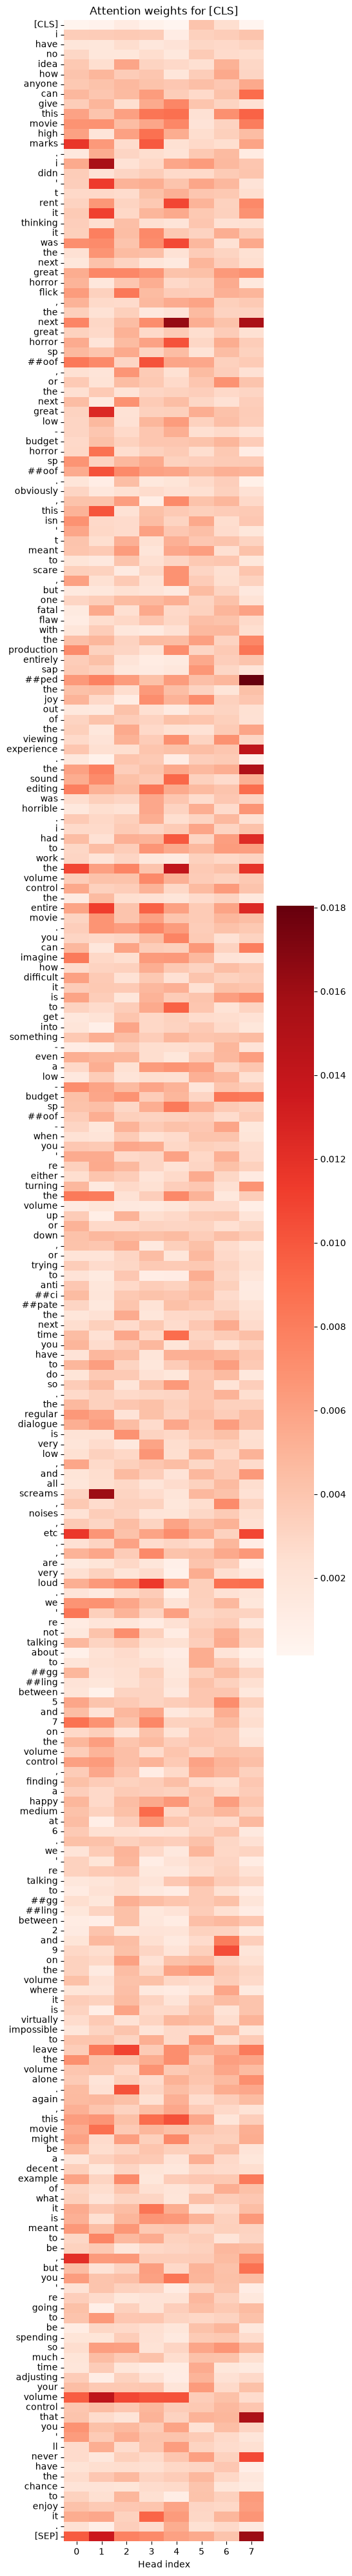

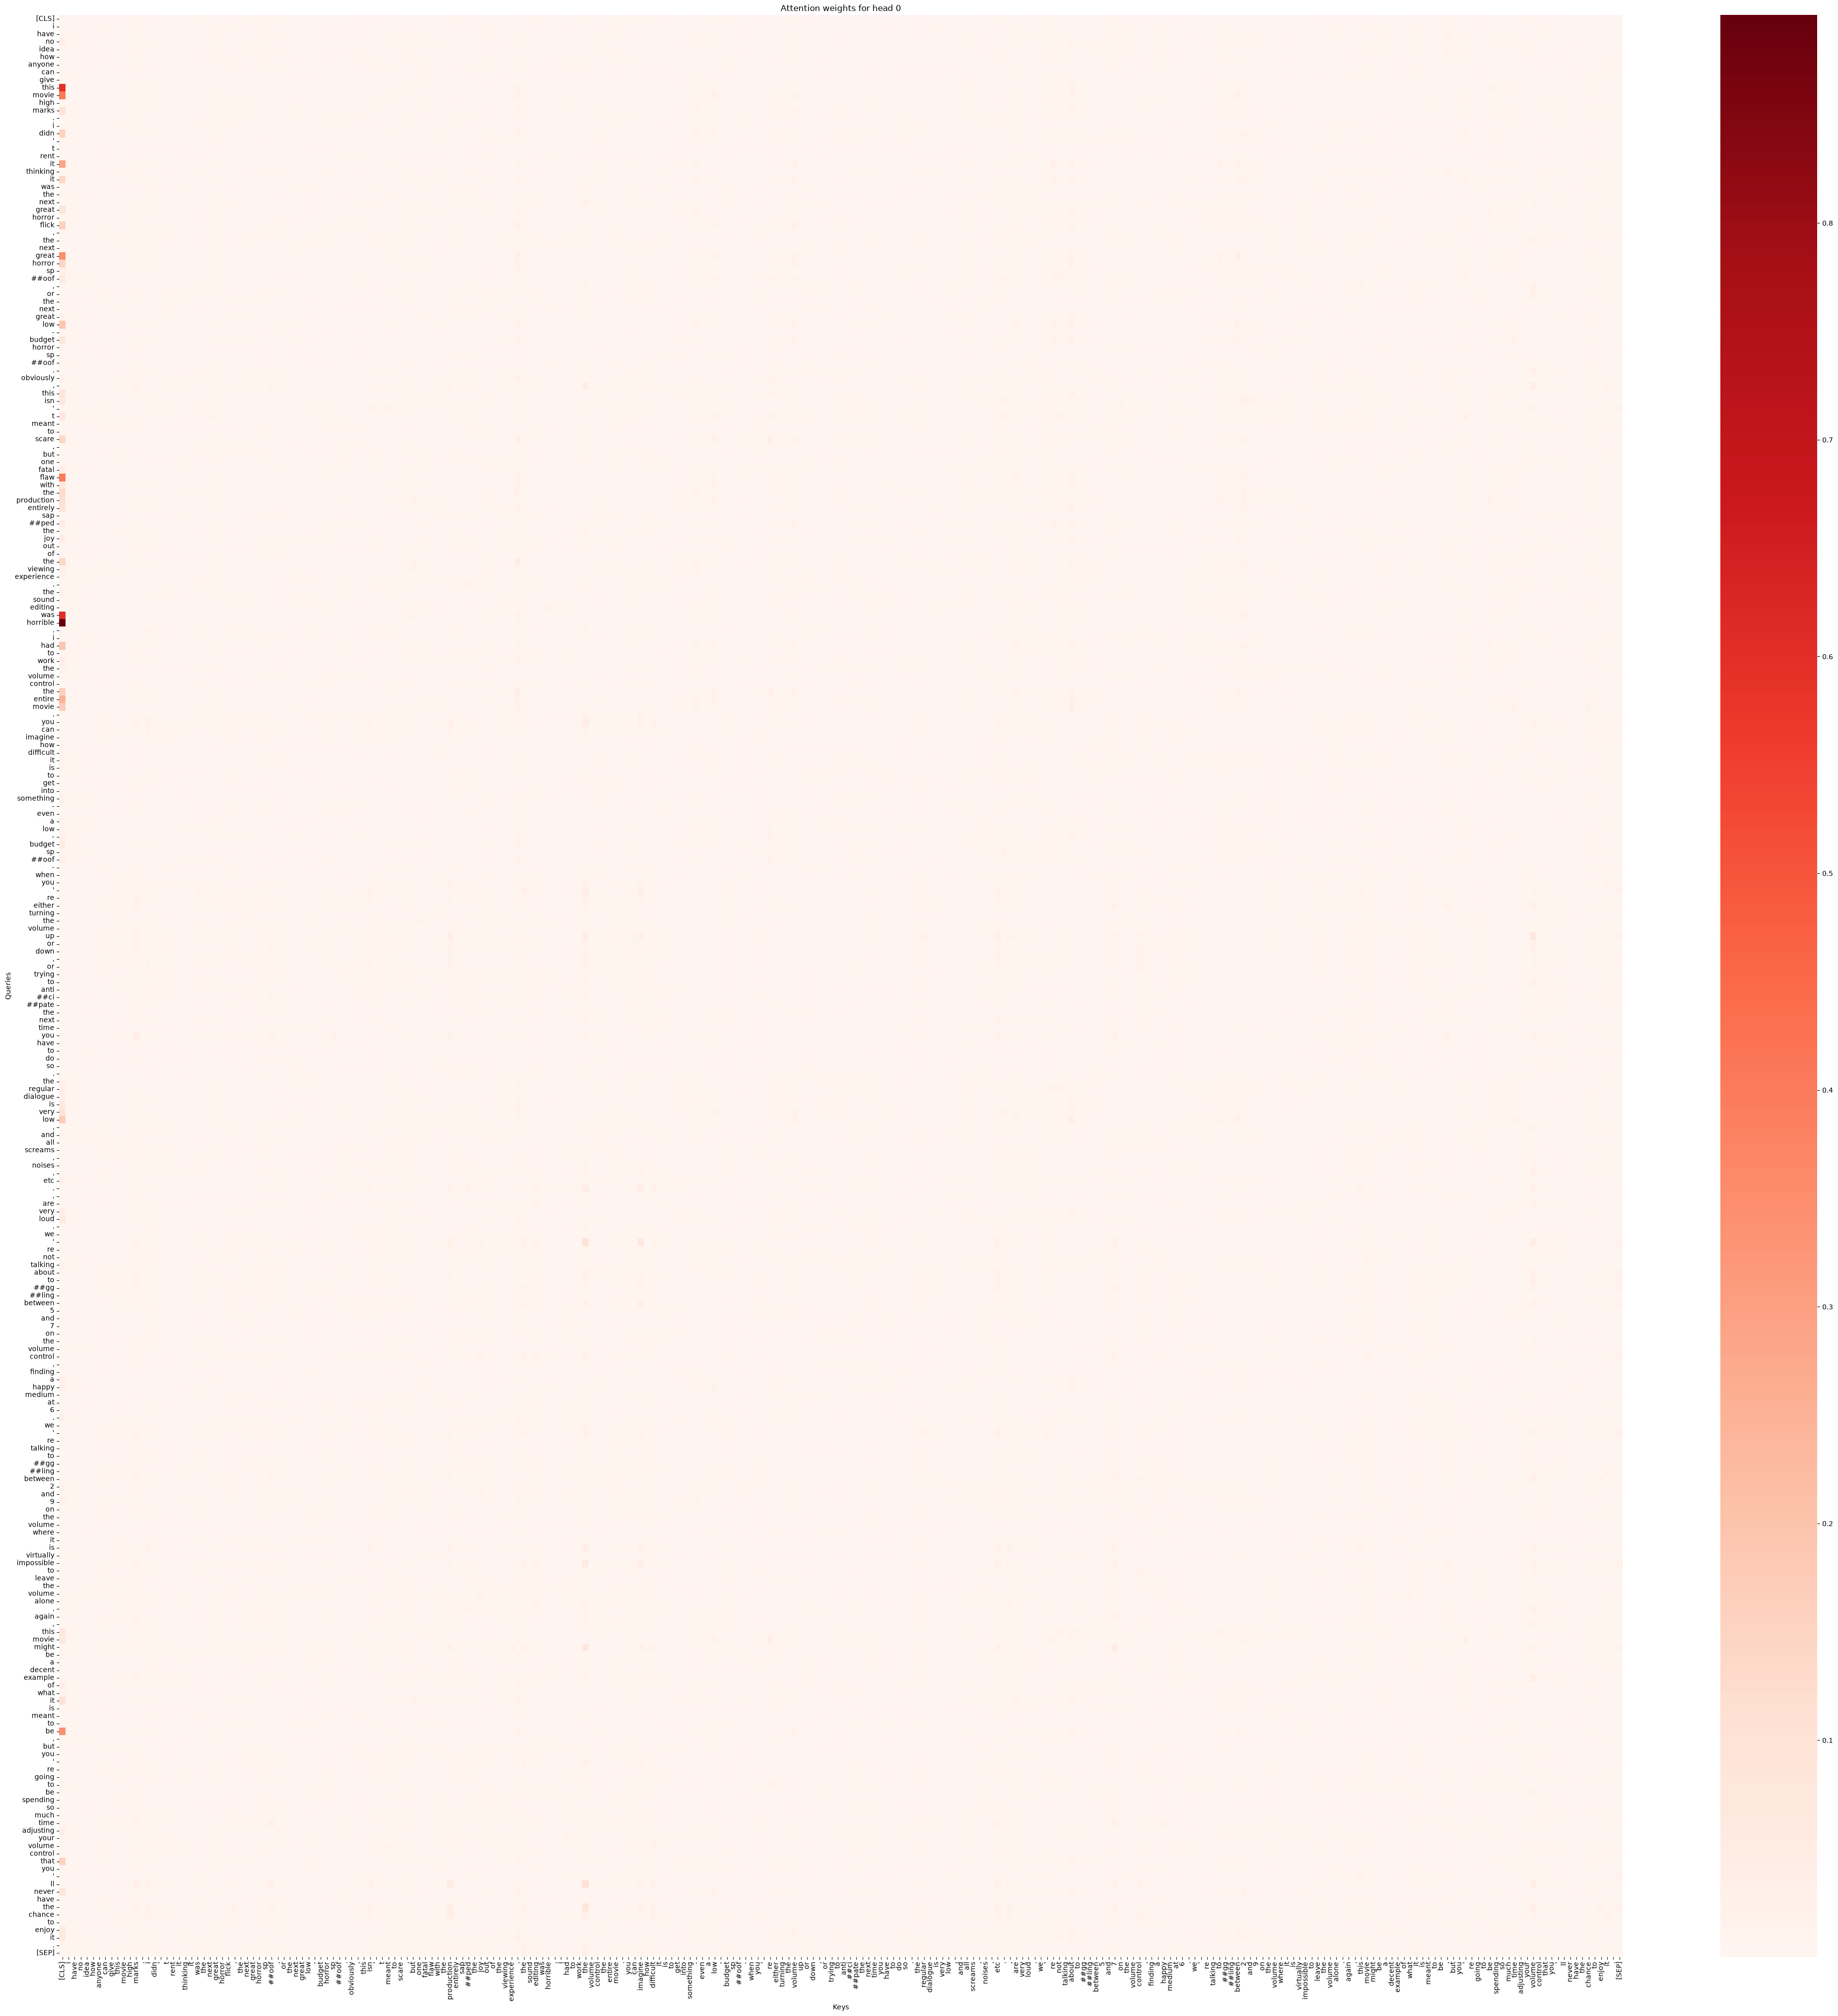

In [44]:
idx = 42
lvl_idx = 0
head_idx = 0


def input_to_tensor(_input, device):
    _input["tokens"] = tokenizer.convert_ids_to_tokens(_input["input_ids"])
    _input["input_ids"] = torch.tensor(
        _input["input_ids"], device=device, dtype=torch.long
    ).reshape(1, -1)
    _input["attention_mask"] = torch.tensor(
        _input["attention_mask"], device=device, dtype=torch.long
    ).reshape(1, -1)
    _input["label"] = torch.tensor(_input["label"], device=device).reshape(1, -1)
    return _input


input_ = input_to_tensor(imdb["test"][idx], device)

with torch.no_grad():
    pred, _ = model(input_["input_ids"], input_["attention_mask"])
    print(f"Predicted probabilities: {pred.exp()}")
    create_attention_plots(model, input_, lvl_idx=lvl_idx, head_idx=head_idx)

You can also test the model on custom inputs. Simply change the `text` to your own text. Play around to find out what makes the model think a review is positive or negative. Try out neutral reviews to see how the model is able to handle them.

Also, try changing the `lvl_idx` and `head_idx` to see how the attention weights change. For looking at the attention weight within the distilBERT model, you can set `attn_key="bert_attn"`.

Predicted probabilities: tensor([[0.9041, 0.0959]])


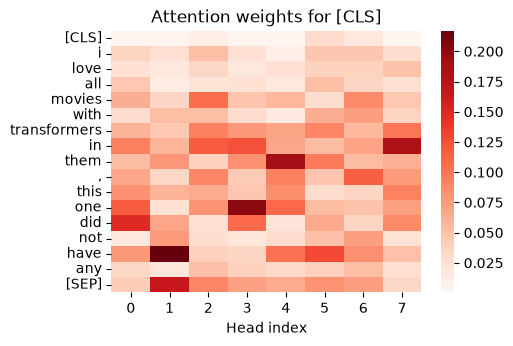

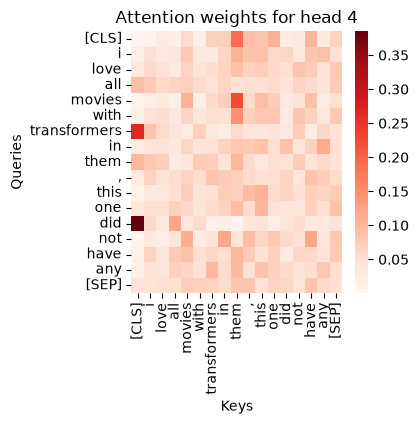

In [46]:
# try out different text by (un)commenting
# text = "i do not have an opinion about the movie. i spend most of my time training neural networks, but my friends say it's 'meh'."
text = "i love all movies with transformers in them, this one did not have any"
# text = "My list of favorite things about this movie is unfortunately an empty one."
lvl_idx = 0
head_idx = 4

input_ = text_to_tensor(text, tokenizer)
# This does not really matter, but for consistency, we add a label here.
input_["label"] = [1]

input_ = input_to_tensor(input_, device)

with torch.no_grad():
    pred, _ = model(input_["input_ids"], input_["attention_mask"])
    print(f"Predicted probabilities: {pred.exp()}")
    create_attention_plots(
        model, input_, lvl_idx=lvl_idx, head_idx=head_idx, attn_key="transformer_attn"
    )

\[extra\]: The above implementation of the transformer is using multi-head self-attention. Briefly describe which parts are different in different heads of the multi-head self-attention layer.

**Your answer:** In multi‑head self‑attention, each head has its own learned query, key, and value projection matrices. Because these projections differ across heads, each head transforms the input into a different representation and therefore computes different attention patterns. This allows different heads to focus on different types of relationships in the sequence.

\[extra\]: What are the benefits of using multi-head self-attention compared to a single-head self-attention block? 

**Your answer:**
Multi‑head self‑attention is more effective because each head has its own learned query, key, and value projections. This allows different heads to attend to different types of relationships and operate in different representation subspaces. As a result, the model captures richer patterns, improves expressiveness, stabilizes training, and learns more nuanced dependencies than a single‑head attention block.

\[extra\]: When applying transformers it is common to have a maximum sequence length. What problems can you foresee when applying transformers to longer sequences?

**Your answer:**
Transformers struggle with long sequences because self‑attention has quadratic time and memory complexity, making computation and storage expensive. Attention weights also become diluted as sequence length grows, making long‑range dependencies harder to learn. Positional encodings often assume a fixed maximum length, so very long sequences can break positional information. Overall, longer sequences lead to higher cost, instability, and degraded model performance.

\[extra\]: In natural language processing, as well as other fields such as computer vision, Transformers have become extremely popular and started replacing standard models such as CNN and RNN. 

What are the main differences between a transformer and an RNN? In particular, how do the differences make it easier to train a transformer, compared to an RNN?

**Your answer:**
The main difference is that RNNs process sequences sequentially, while transformers process all tokens in parallel using self‑attention. This removes recurrence and long chains of dependencies, which eliminates vanishing gradients, makes long‑range relationships easy to learn, and allows efficient GPU parallelization. Multi‑head attention also gives transformers richer representations than the single hidden state of an RNN. Together, these differences make transformers far easier and more stable to train compared to RNNs.

### Learned token embedding
We can also inspect the learned embeddings of the tokens for the distilBERT model. Each token is mapped to a learned vector before being processed by the Transformer. We can list the embeddings and corresponding tokens with largest cosine similarity to a given token. 

Try different words to get an intuition for how this works. Interesting examples can be "good", "four", "actor", or words with multiple meanings such as "feet" or "watch". Are the results what you'd expect?

In [47]:
word = "yes"
topk = 10
token_embeddings = model.bert.bert.embeddings.word_embeddings.weight

# The first token will be the CLS token, while the last token will be the SEP token.
# We ignore these tokens.
tokenized_word = tokenizer(word, truncation=True).input_ids[1:-1]

# Use mean in case word consists of multiple tokens.
word_embedding = token_embeddings[tokenized_word].mean(dim=0, keepdim=True)

similarity = F.cosine_similarity(word_embedding, token_embeddings, dim=1)
similarity = similarity.cpu()

_, idx = torch.topk(similarity, k=topk)

print(f"{topk} most similar words to {word}")
for i in range(topk):
    print(f"{i}. {tokenizer.convert_ids_to_tokens(idx[i].item())}")

10 most similar words to yes
0. yes
1. yeah
2. aye
3. yep
4. hello
5. nay
6. nodded
7. ##yes
8. 1729
9. 1734


The word embeddings seem to capture the semantic meaning of the words in a sense that they are more similar to synonyms than other words in the vocabulary. If this is the case, why do we need to use advanced networks such as Transformers to process them further for classification?

**Your answer:** 
Word embeddings only capture the static semantic meaning of individual words. They do not model context, word interactions, sentence structure, or long‑range dependencies. Transformers use self‑attention to create contextual embeddings and learn how words influence each other, enabling reasoning over entire sentences. This makes them far more powerful and necessary for tasks like classification, even when the underlying word embeddings already look semantically meaningful.

We can also inspect the positional embeddings of the distilBERT model. Below we draw a heatmap for the cosine similarity between the learned positional embeddings. We only draw this for the first `first_k` tokens, feel free to inspect other ranges as well.

<Axes: >

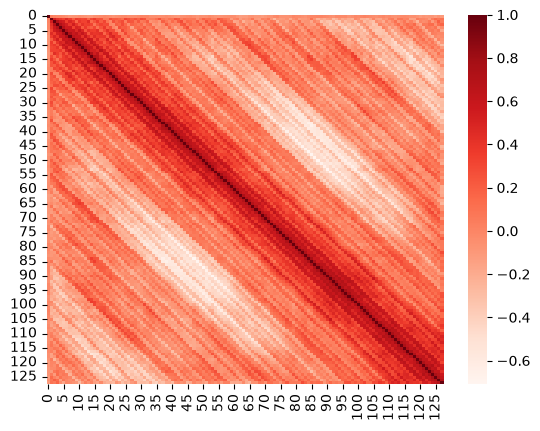

In [48]:
first_k = 128

pos_embeddings = model.bert.bert.embeddings.position_embeddings.weight
sims = pos_embeddings @ pos_embeddings.T
pos_emb_norm = torch.norm(pos_embeddings, dim=1)
sims = sims / (pos_emb_norm.unsqueeze(1) @ pos_emb_norm.unsqueeze(0))

sns.heatmap(sims.cpu().detach().numpy()[:first_k, :first_k], cmap="Reds")

\[extra\]: When training the RNN in part 1, we did not need any positional embeddings. 

Why do we need them now? What would happen if we did not use them? Also, are there any applications where you do not need them when using a Transformer (please be specific here)?

**Your answer:** RNNs do not need positional embeddings because recurrence inherently encodes order. Transformers process all tokens in parallel, so they have no built‑in notion of sequence order. Without positional embeddings, a Transformer would treat the input as an unordered set of tokens, losing grammar, structure, and meaning. However, in tasks where the input is naturally order‑invariant such as Set Transformers, some Vision Transformer variants, and certain graph models positional embeddings are unnecessary.

\[extra\]: Why do we see these particular patterns in the heatmap above?

**Your answer:** We see a strong diagonal and smooth bands because nearby positions have similar learned embeddings, while distant positions differ more, reflecting how BERT has internalized sequence order and typical positional roles during training.

\[extra\]: The first positional embedding (the one for the [CLS] token) has a different pattern than the other embeddings. Why? You can think of the implications in the Transformer if this wasn't the case.

**Your answer:** The [CLS] positional embedding looks different because the [CLS] token does not represent a real position in the sentence. It acts as a special summary token used for classification, so the model learns a distinct positional embedding for it. If its embedding looked like the others, the Transformer would treat [CLS] as a normal word, making it harder for attention heads to use it as a global aggregator. In tasks where a special summary token is needed, its positional embedding must be different from the regular positional embeddings.

# Wrapping up

The transformer architecture has become incredibly popular and has produced truly amazing results.
You should now have a good insight for how they can be implemented in `pytorch`. If you are interested, here are some more resources:

- https://pytorch.org/docs/stable/generated/torch.nn.Transformer.html
- https://github.com/huggingface/transformers